# No-Prop IAC Grid Search Results

Summarizes the hyperparameter grid search in `no_prop_iac_grid_results.csv` (driven by `nopo-iac-grid-20260518-012036.out`).

Each row is one hyperparameter combination evaluated on the IAC multitask setup with 8 binary tasks. Metrics include `overall_*` aggregates and per-task `accuracy`, `precision`, `recall`, `f1`, `auc`, `average_precision`.

Sections:
1. Load & inspect the grid
2. Overall performance (table + graphs)
3. Top configurations by `primary_metric`
4. Per-task performance (table + graphs)
5. Hyperparameter effects on `primary_metric`
6. **Best hyperparameters per metric** — for each overall and per-task metric, identify the full combo that maximizes it and the marginal best value for each individual hyperparameter

In [44]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

CSV_PATH = Path("no_prop_iac_grid_results.csv")
df = pd.read_csv(CSV_PATH)
print(f"Loaded {len(df)} rows from {CSV_PATH}")
print(f"Columns: {len(df.columns)}")
df.head()

Loaded 32 rows from no_prop_iac_grid_results.csv
Columns: 60


,combo_index,optimizer,learning_rate,weight_decay_rate,warmup_fraction,batch_size,dropout_rate,overall_f1,overall_average_precision,overall_auc,overall_accuracy,primary_metric,task_attacking_respectful_bi_accuracy,task_attacking_respectful_bi_precision,task_attacking_respectful_bi_recall,task_attacking_respectful_bi_f1,task_attacking_respectful_bi_auc,task_attacking_respectful_bi_average_precision,task_defeater_undercutter_bi_accuracy,task_defeater_undercutter_bi_precision,task_defeater_undercutter_bi_recall,task_defeater_undercutter_bi_f1,task_defeater_undercutter_bi_auc,task_defeater_undercutter_bi_average_precision,task_disagree_agree_bi_accuracy,task_disagree_agree_bi_precision,task_disagree_agree_bi_recall,task_disagree_agree_bi_f1,task_disagree_agree_bi_auc,task_disagree_agree_bi_average_precision,task_emotion_fact_bi_accuracy,task_emotion_fact_bi_precision,task_emotion_fact_bi_recall,task_emotion_fact_bi_f1,task_emotion_fact_bi_auc,task_emotion_fact_bi_average_precision,task_nasty_nice_bi_accuracy,task_nasty_nice_bi_precision,task_nasty_nice_bi_recall,task_nasty_nice_bi_f1,task_nasty_nice_bi_auc,task_nasty_nice_bi_average_precision,task_negotiate_attack_bi_accuracy,task_negotiate_attack_bi_precision,task_negotiate_attack_bi_recall,task_negotiate_attack_bi_f1,task_negotiate_attack_bi_auc,task_negotiate_attack_bi_average_precision,task_personal_audience_bi_accuracy,task_personal_audience_bi_precision,task_personal_audience_bi_recall,task_personal_audience_bi_f1,task_personal_audience_bi_auc,task_personal_audience_bi_average_precision,task_questioning_asserting_bi_accuracy,task_questioning_asserting_bi_precision,task_questioning_asserting_bi_recall,task_questioning_asserting_bi_f1,task_questioning_asserting_bi_auc,task_questioning_asserting_bi_average_precision
0,25,adamw,0.0003,0.0100,0.0500,128,0.2000,0.6493,0.6482,0.6251,0.6533,0.6493,0.5902,0.6415,0.5902,0.5998,0.6358,0.5075,0.6048,0.5747,0.6048,0.5727,0.5427,0.6525,0.7370,0.6837,0.7370,0.7033,0.5028,0.7970,0.6673,0.6696,0.6673,0.6683,0.7089,0.7828,0.6209,0.6974,0.6209,0.6406,0.6730,0.4737,0.6515,0.6530,0.6515,0.6518,0.6891,0.7092,0.7002,0.7069,0.7002,0.7034,0.6253,0.8189,0.6545,0.6548,0.6545,0.6546,0.6233,0.4441
1,7,adamw,0.0001,0.0050,0.1000,256,0.2000,0.6422,0.6356,0.6220,0.6431,0.6422,0.5972,0.6388,0.5972,0.6067,0.6345,0.4956,0.6065,0.5837,0.6065,0.5854,0.5490,0.6525,0.7480,0.6906,0.7480,0.7095,0.5120,0.7910,0.6717,0.6722,0.6717,0.6719,0.7088,0.7763,0.6273,0.7039,0.6273,0.6467,0.6692,0.4338,0.6398,0.6582,0.6398,0.6353,0.6829,0.7026,0.6326,0.6989,0.6326,0.6546,0.6151,0.8095,0.6215,0.6352,0.6215,0.6272,0.6044,0.4230
2,19,adamw,0.0003,0.0050,0.0500,256,0.2000,0.6400,0.6497,0.6323,0.6353,0.6400,0.5897,0.6403,0.5897,0.5992,0.6370,0.5155,0.6145,0.5871,0.6145,0.5832,0.5424,0.6419,0.6483,0.6890,0.6483,0.6657,0.5461,0.8158,0.6464,0.6752,0.6464,0.6502,0.7163,0.7860,0.6186,0.7004,0.6186,0.6387,0.6724,0.4739,0.6633,0.6649,0.6633,0.6635,0.6953,0.7127,0.6458,0.7128,0.6458,0.6672,0.6270,0.8183,0.6557,0.6490,0.6557,0.6519,0.6219,0.4337
3,29,adamw,0.0003,0.0100,0.1000,128,0.2000,0.6387,0.6512,0.6285,0.6411,0.6387,0.5502,0.6509,0.5502,0.5527,0.6372,0.5166,0.5774,0.5608,0.5774,0.5658,0.5384,0.6389,0.7219,0.6945,0.7219,0.7063,0.5278,0.8070,0.6877,0.6808,0.6877,0.6782,0.7114,0.7865,0.5628,0.7165,0.5628,0.5815,0.6783,0.4863,0.6515,0.6530,0.6515,0.6518,0.6862,0.7103,0.7166,0.7166,0.7166,0.7166,0.6287,0.8158,0.6606,0.6533,0.6606,0.6565,0.6200,0.4483
4,31,adamw,0.0003,0.0100,0.1000,256,0.2000,0.6351,0.6511,0.6341,0.6287,0.6351,0.5583,0.6500,0.5583,0.5629,0.6406,0.5218,0.6226,0.6000,0.6226,0.5976,0.5521,0.6449,0.5852,0.6910,0.5852,0.6204,0.5490,0.8213,0.6775,0.6738,0.6775,0.6751,0.7139,0.7861,0.6517,0.6967,0.6517,0.6666,0.6831,0.4963,0.6501,0.6537,0.6501,0.6502,0.6901,0.7132,0.6491,0.7047,0.6491,0.6684,0.6233,0.8051,0.6349,0.6457,0.6349,0.6395,0.6208,0.4204


In [45]:
HPARAM_COLS = [
    "combo_index",
    "optimizer",
    "learning_rate",
    "weight_decay_rate",
    "warmup_fraction",
    "batch_size",
    "dropout_rate",
]
HPARAM_VALUE_COLS = [
    "optimizer",
    "learning_rate",
    "weight_decay_rate",
    "warmup_fraction",
    "batch_size",
    "dropout_rate",
]
OVERALL_COLS = [c for c in df.columns if c.startswith("overall_")] + ["primary_metric"]
TASK_COLS = [c for c in df.columns if c.startswith("task_")]

# Per-task metric suffixes (longest first so `average_precision` matches before `precision`).
METRIC_SUFFIXES = ("average_precision", "accuracy", "precision", "recall", "f1", "auc")

def parse_task_col(col):
    stripped = col.replace("task_", "")
    for suffix in METRIC_SUFFIXES:
        if stripped.endswith("_" + suffix):
            return stripped[: -(len(suffix) + 1)], suffix
    raise ValueError(f"unrecognized task column: {col}")

TASKS = sorted({parse_task_col(c)[0] for c in TASK_COLS})
METRICS_PER_TASK = sorted({parse_task_col(c)[1] for c in TASK_COLS})

print(f"Tasks ({len(TASKS)}): {TASKS}")
print(f"Per-task metrics: {METRICS_PER_TASK}")
print(f"Overall metric cols: {OVERALL_COLS}")

Tasks (8): ['attacking_respectful_bi', 'defeater_undercutter_bi', 'disagree_agree_bi', 'emotion_fact_bi', 'nasty_nice_bi', 'negotiate_attack_bi', 'personal_audience_bi', 'questioning_asserting_bi']
Per-task metrics: ['accuracy', 'auc', 'average_precision', 'f1', 'precision', 'recall']
Overall metric cols: ['overall_f1', 'overall_average_precision', 'overall_auc', 'overall_accuracy', 'primary_metric']


## 2. Overall performance across the grid

Distribution of each `overall_*` metric over the 32 hyperparameter combinations.

In [46]:
overall_stats = df[OVERALL_COLS].agg(["min", "mean", "median", "max", "std"]).T
overall_stats["range"] = overall_stats["max"] - overall_stats["min"]
overall_stats

,min,mean,median,max,std,range
overall_f1,0.4692,0.5944,0.5949,0.6493,0.0398,0.1801
overall_average_precision,0.5366,0.6417,0.6463,0.6614,0.0210,0.1248
overall_auc,0.5039,0.6207,0.6244,0.6389,0.0224,0.1349
overall_accuracy,0.5110,0.5973,0.5921,0.6533,0.0329,0.1423
primary_metric,0.4692,0.5944,0.5949,0.6493,0.0398,0.1801


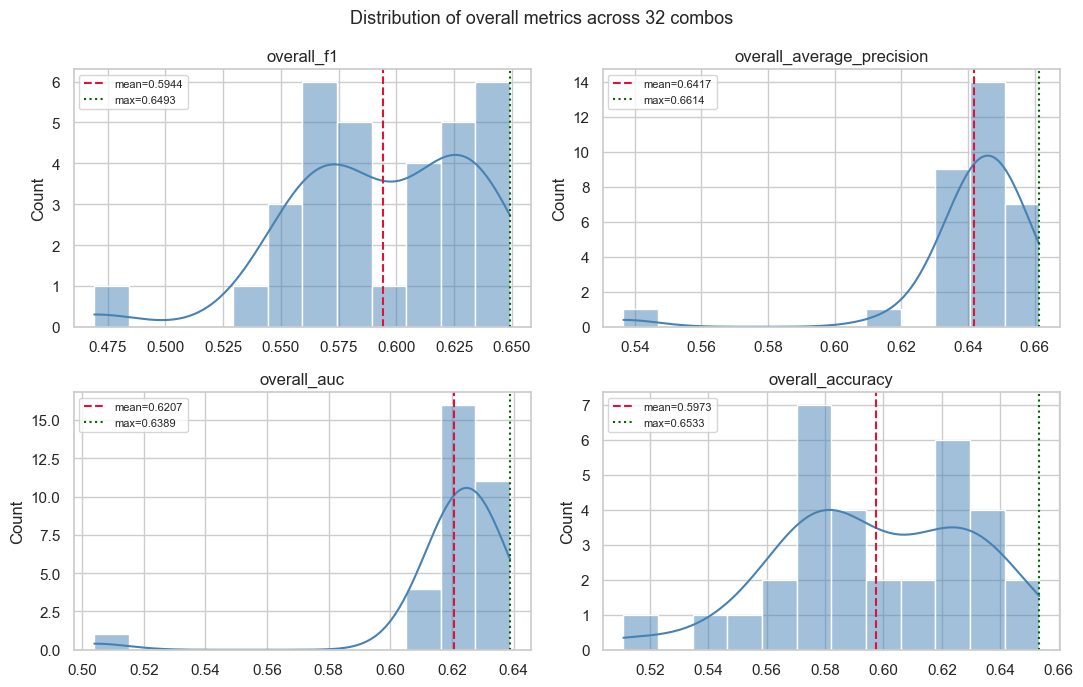

In [47]:
metrics_to_plot = ["overall_f1", "overall_average_precision", "overall_auc", "overall_accuracy"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=False)
for ax, metric in zip(axes.flat, metrics_to_plot):
    sns.histplot(df[metric], bins=12, kde=True, ax=ax, color="steelblue")
    ax.axvline(df[metric].mean(), color="crimson", linestyle="--", label=f"mean={df[metric].mean():.4f}")
    ax.axvline(df[metric].max(), color="darkgreen", linestyle=":", label=f"max={df[metric].max():.4f}")
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.legend(fontsize=8)
fig.suptitle("Distribution of overall metrics across 32 combos", fontsize=13)
fig.tight_layout()
plt.show()

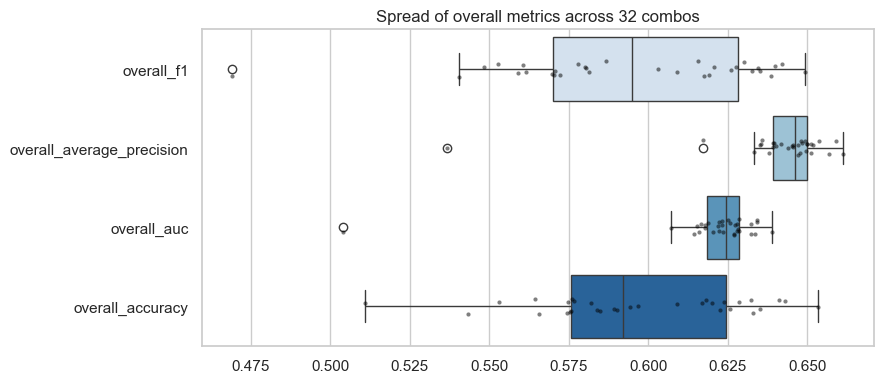

In [48]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=df[metrics_to_plot], orient="h", ax=ax, palette="Blues")
sns.stripplot(data=df[metrics_to_plot], orient="h", ax=ax, color="black", size=3, alpha=0.5)
ax.set_title("Spread of overall metrics across 32 combos")
fig.tight_layout()
plt.show()

## 3. Top configurations

Top/bottom 5 combos and all-combo rankings, broken out **for each of the four distinct overall metrics**: `overall_f1`, `overall_average_precision`, `overall_auc`, `overall_accuracy`. (`primary_metric` is omitted because it duplicates `overall_f1`.)

Different metrics can disagree on which combo is best — comparing them side-by-side surfaces that.

In [49]:
TOP_K = 5
UNIQUE_OVERALL = ["overall_f1", "overall_average_precision", "overall_auc", "overall_accuracy"]

def _ranked_slice(metric_col, k, ascending):
    sub = df.sort_values(metric_col, ascending=ascending).head(k).copy()
    sub = sub[HPARAM_COLS + [metric_col]].reset_index(drop=True)
    sub.insert(0, "rank", sub.index + 1)
    sub.insert(0, "metric", metric_col)
    return sub.rename(columns={metric_col: "value"})

top_by_metric = pd.concat(
    [_ranked_slice(m, TOP_K, ascending=False) for m in UNIQUE_OVERALL],
    ignore_index=True,
).set_index(["metric", "rank"])
print(f"Top {TOP_K} combos for each overall metric:")
top_by_metric

Top 5 combos for each overall metric:


combo_index optimizer  learning_rate  weight_decay_rate  warmup_fraction  batch_size  dropout_rate  value
metric                    rank                                                                                                           
overall_f1                1              25     adamw         0.0003             0.0100           0.0500         128        0.2000 0.6493
                          2               7     adamw         0.0001             0.0050           0.1000         256        0.2000 0.6422
                          3              19     adamw         0.0003             0.0050           0.0500         256        0.2000 0.6400
                          4              29     adamw         0.0003             0.0100           0.1000         128        0.2000 0.6387
                          5              31     adamw         0.0003             0.0100           0.1000         256        0.2000 0.6351
overall_average_precision 1               5     adamw         0.0001             0.0050           0.1000         128        0.2000 0.6614
                          2               9     adamw         0.0001             0.0100           0.0500         128        0.2000 0.6591
                          3               1     adamw         0.0001             0.0050           0.0500         128        0.2000 0.6567
                          4              13     adamw         0.0001             0.0100           0.1000         128        0.2000 0.6536
                          5              10     adamw         0.0001             0.0100           0.0500         128        0.4000 0.6520
overall_auc               1               9     adamw         0.0001             0.0100           0.0500         128        0.2000 0.6389
                          2              13     adamw         0.0001             0.0100           0.1000         128        0.2000 0.6342
                          3              31     adamw         0.0003             0.0100           0.1000         256        0.2000 0.6341
                          4               5     adamw         0.0001             0.0050           0.1000         128        0.2000 0.6336
                          5               1     adamw         0.0001             0.0050           0.0500         128        0.2000 0.6323
overall_accuracy          1              25     adamw         0.0003             0.0100           0.0500         128        0.2000 0.6533
                          2               7     adamw         0.0001             0.0050           0.1000         256        0.2000 0.6431
                          3              29     adamw         0.0003             0.0100           0.1000         128        0.2000 0.6411
                          4              19     adamw         0.0003             0.0050           0.0500         256        0.2000 0.6353
                          5              16     adamw         0.0001             0.0100           0.1000         256        0.4000 0.6329

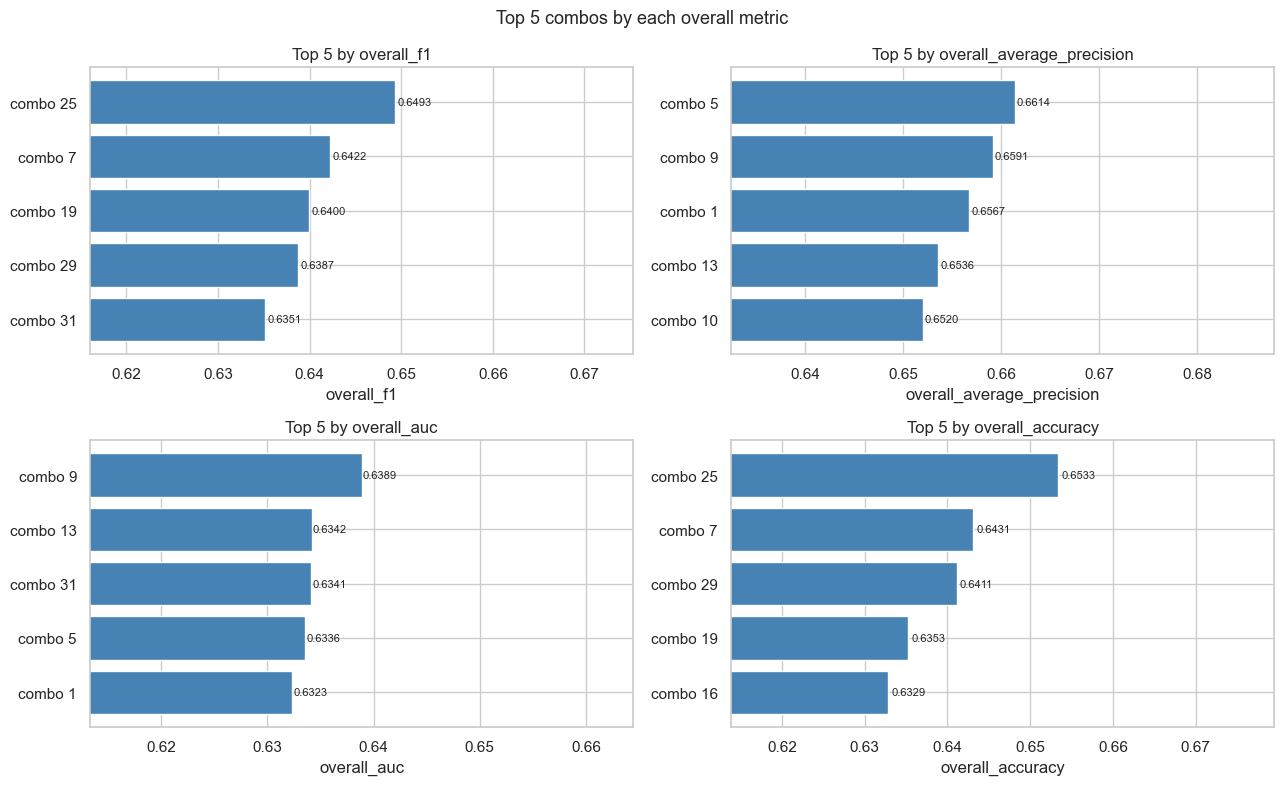

In [50]:
# Top-K combos for each overall metric — one subplot per metric.
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=False)
for ax, metric in zip(axes.flat, UNIQUE_OVERALL):
    top = df.sort_values(metric, ascending=False).head(TOP_K)
    # Reverse so rank 1 is at the top of the horizontal bar chart.
    combos = top["combo_index"].astype(int).tolist()[::-1]
    values = top[metric].tolist()[::-1]
    bars = ax.barh(range(len(values)), values, color="steelblue")
    ax.set_yticks(range(len(values)))
    ax.set_yticklabels([f"combo {c}" for c in combos])
    ax.set_xlabel(metric)
    ax.set_title(f"Top {TOP_K} by {metric}")
    pad = (max(values) - min(values)) * 0.02 or 0.001
    for i, v in enumerate(values):
        ax.text(v + pad, i, f"{v:.4f}", va="center", fontsize=8)
    ax.set_xlim(min(values) * 0.97, max(values) * 1.04)
fig.suptitle(f"Top {TOP_K} combos by each overall metric", fontsize=13)
fig.tight_layout()
plt.show()

In [51]:
bottom_by_metric = pd.concat(
    [_ranked_slice(m, TOP_K, ascending=True) for m in UNIQUE_OVERALL],
    ignore_index=True,
).set_index(["metric", "rank"])
print(f"Worst {TOP_K} combos for each overall metric:")
bottom_by_metric

Worst 5 combos for each overall metric:


combo_index optimizer  learning_rate  weight_decay_rate  warmup_fraction  batch_size  dropout_rate  value
metric                    rank                                                                                                           
overall_f1                1              30     adamw         0.0003             0.0100           0.1000         128        0.4000 0.4692
                          2              14     adamw         0.0001             0.0100           0.1000         128        0.4000 0.5403
                          3               2     adamw         0.0001             0.0050           0.0500         128        0.4000 0.5483
                          4              18     adamw         0.0003             0.0050           0.0500         128        0.4000 0.5527
                          5              26     adamw         0.0003             0.0100           0.0500         128        0.4000 0.5589
overall_average_precision 1              30     adamw         0.0003             0.0100           0.1000         128        0.4000 0.5366
                          2               8     adamw         0.0001             0.0050           0.1000         256        0.4000 0.6172
                          3              26     adamw         0.0003             0.0100           0.0500         128        0.4000 0.6333
                          4              20     adamw         0.0003             0.0050           0.0500         256        0.4000 0.6351
                          5               7     adamw         0.0001             0.0050           0.1000         256        0.2000 0.6356
overall_auc               1              30     adamw         0.0003             0.0100           0.1000         128        0.4000 0.5039
                          2               8     adamw         0.0001             0.0050           0.1000         256        0.4000 0.6072
                          3              20     adamw         0.0003             0.0050           0.0500         256        0.4000 0.6143
                          4              32     adamw         0.0003             0.0100           0.1000         256        0.4000 0.6153
                          5              26     adamw         0.0003             0.0100           0.0500         128        0.4000 0.6161
overall_accuracy          1              30     adamw         0.0003             0.0100           0.1000         128        0.4000 0.5110
                          2              14     adamw         0.0001             0.0100           0.1000         128        0.4000 0.5433
                          3               2     adamw         0.0001             0.0050           0.0500         128        0.4000 0.5532
                          4              27     adamw         0.0003             0.0100           0.0500         256        0.2000 0.5643
                          5              18     adamw         0.0003             0.0050           0.0500         128        0.4000 0.5656

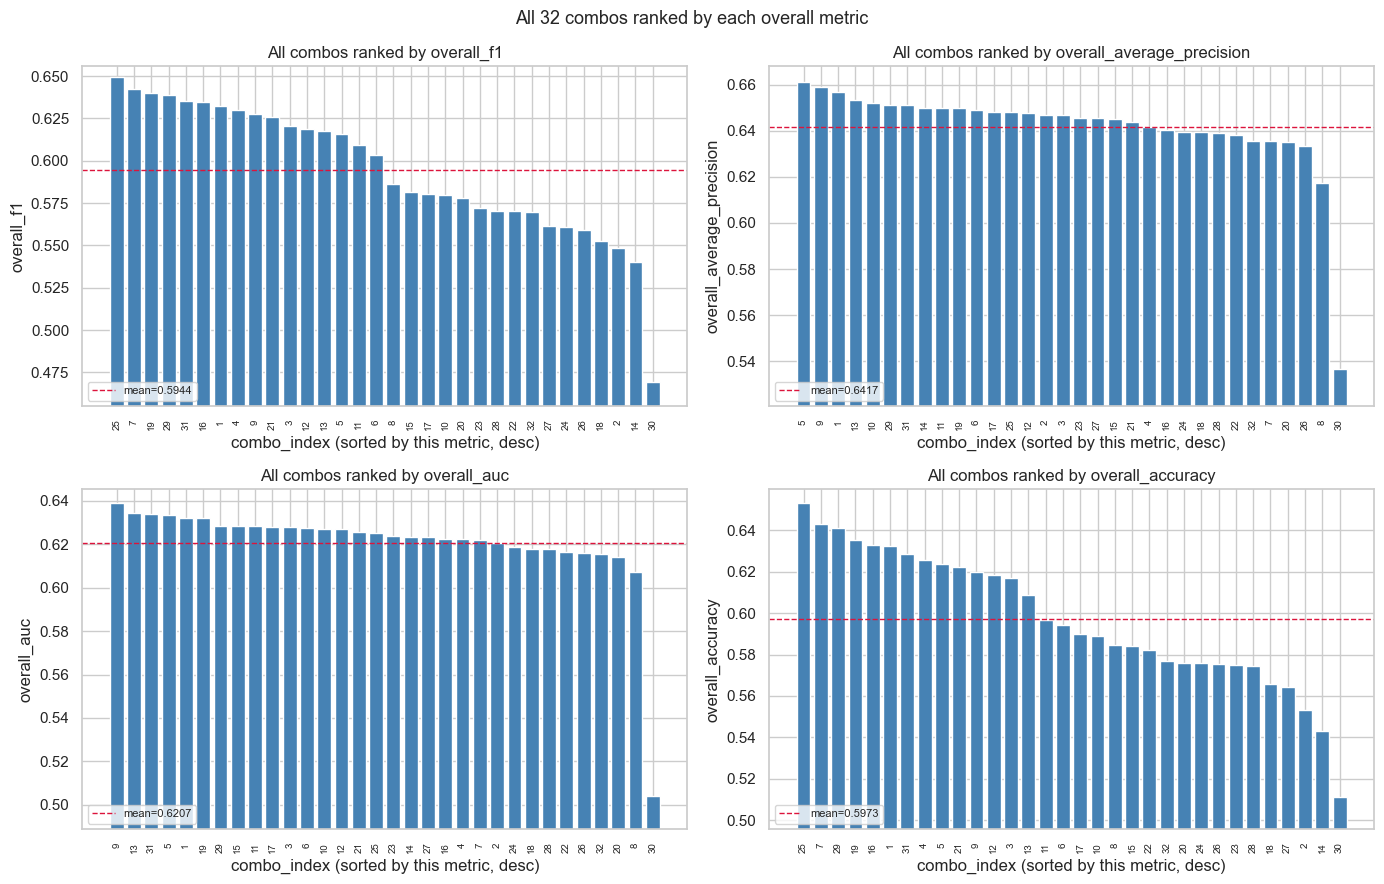

In [52]:
# All 32 combos ranked by each overall metric — one subplot per metric.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, metric in zip(axes.flat, UNIQUE_OVERALL):
    ranked = df.sort_values(metric, ascending=False).reset_index(drop=True)
    x = np.arange(len(ranked))
    ax.bar(x, ranked[metric], color="steelblue")
    ax.set_xticks(x)
    ax.set_xticklabels(ranked["combo_index"].astype(int), rotation=90, fontsize=7)
    ax.set_xlabel("combo_index (sorted by this metric, desc)")
    ax.set_ylabel(metric)
    ax.set_title(f"All combos ranked by {metric}")
    ax.axhline(ranked[metric].mean(), color="crimson", linestyle="--", linewidth=1, label=f"mean={ranked[metric].mean():.4f}")
    ax.set_ylim(ranked[metric].min() * 0.97, ranked[metric].max() * 1.01)
    ax.legend(fontsize=8, loc="lower left")
fig.suptitle("All 32 combos ranked by each overall metric", fontsize=13)
fig.tight_layout()
plt.show()

## 4. Per-task performance

For each of the 8 binary tasks, summarize the distribution of each per-task metric across the 32 combos, then plot.

In [53]:
records = []
for col in TASK_COLS:
    task, metric = parse_task_col(col)
    for combo_idx, value in zip(df["combo_index"], df[col]):
        records.append({"combo_index": combo_idx, "task": task, "metric": metric, "value": value})
long_df = pd.DataFrame.from_records(records)
long_df.head()

,combo_index,task,metric,value
0,25,attacking_respectful_bi,accuracy,0.5902
1,7,attacking_respectful_bi,accuracy,0.5972
2,19,attacking_respectful_bi,accuracy,0.5897
3,29,attacking_respectful_bi,accuracy,0.5502
4,31,attacking_respectful_bi,accuracy,0.5583


In [54]:
per_task_mean = (
    long_df.groupby(["task", "metric"])["value"].mean().unstack("metric").sort_index()
)
print("Mean across 32 combos, per task x metric:")
per_task_mean

Mean across 32 combos, per task x metric:


metric,accuracy,auc,average_precision,f1,precision,recall
task,,,,,,
attacking_respectful_bi,0.5773,0.6323,0.5116,0.5798,0.6420,0.5773
defeater_undercutter_bi,0.5944,0.5384,0.6433,0.5603,0.5915,0.5944
disagree_agree_bi,0.4399,0.5225,0.8083,0.4167,0.7181,0.4399
emotion_fact_bi,0.6615,0.7049,0.7785,0.6617,0.6690,0.6615
nasty_nice_bi,0.5895,0.6686,0.4705,0.6057,0.7041,0.5895
negotiate_attack_bi,0.6447,0.6822,0.7049,0.6433,0.6526,0.6447
personal_audience_bi,0.6730,0.6147,0.8091,0.6842,0.7062,0.6730
questioning_asserting_bi,0.5983,0.6024,0.4073,0.6040,0.6418,0.5983


In [55]:
per_task_max = (
    long_df.groupby(["task", "metric"])["value"].max().unstack("metric").sort_index()
)
print("Best (max) across 32 combos, per task x metric:")
per_task_max

Best (max) across 32 combos, per task x metric:


metric,accuracy,auc,average_precision,f1,precision,recall
task,,,,,,
attacking_respectful_bi,0.6494,0.6580,0.5493,0.6492,0.6534,0.6494
defeater_undercutter_bi,0.6468,0.5655,0.6578,0.5976,0.6573,0.6468
disagree_agree_bi,0.7480,0.5673,0.8291,0.7095,0.7880,0.7480
emotion_fact_bi,0.6882,0.7202,0.7966,0.6796,0.6830,0.6882
nasty_nice_bi,0.6779,0.6965,0.5184,0.6876,0.7193,0.6779
negotiate_attack_bi,0.6647,0.7029,0.7225,0.6650,0.6748,0.6647
personal_audience_bi,0.7315,0.6390,0.8259,0.7258,0.7213,0.7315
questioning_asserting_bi,0.6606,0.6235,0.4483,0.6565,0.6595,0.6606


/var/folders/0s/hmhms5h943d0b4ct3l6b61700000gn/T/ipykernel_9515/28115402.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, y="task", x="value", order=order, ax=ax, palette="viridis")
/var/folders/0s/hmhms5h943d0b4ct3l6b61700000gn/T/ipykernel_9515/28115402.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, y="task", x="value", order=order, ax=ax, palette="viridis")
/var/folders/0s/hmhms5h943d0b4ct3l6b61700000gn/T/ipykernel_9515/28115402.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, y="task", x="value", o

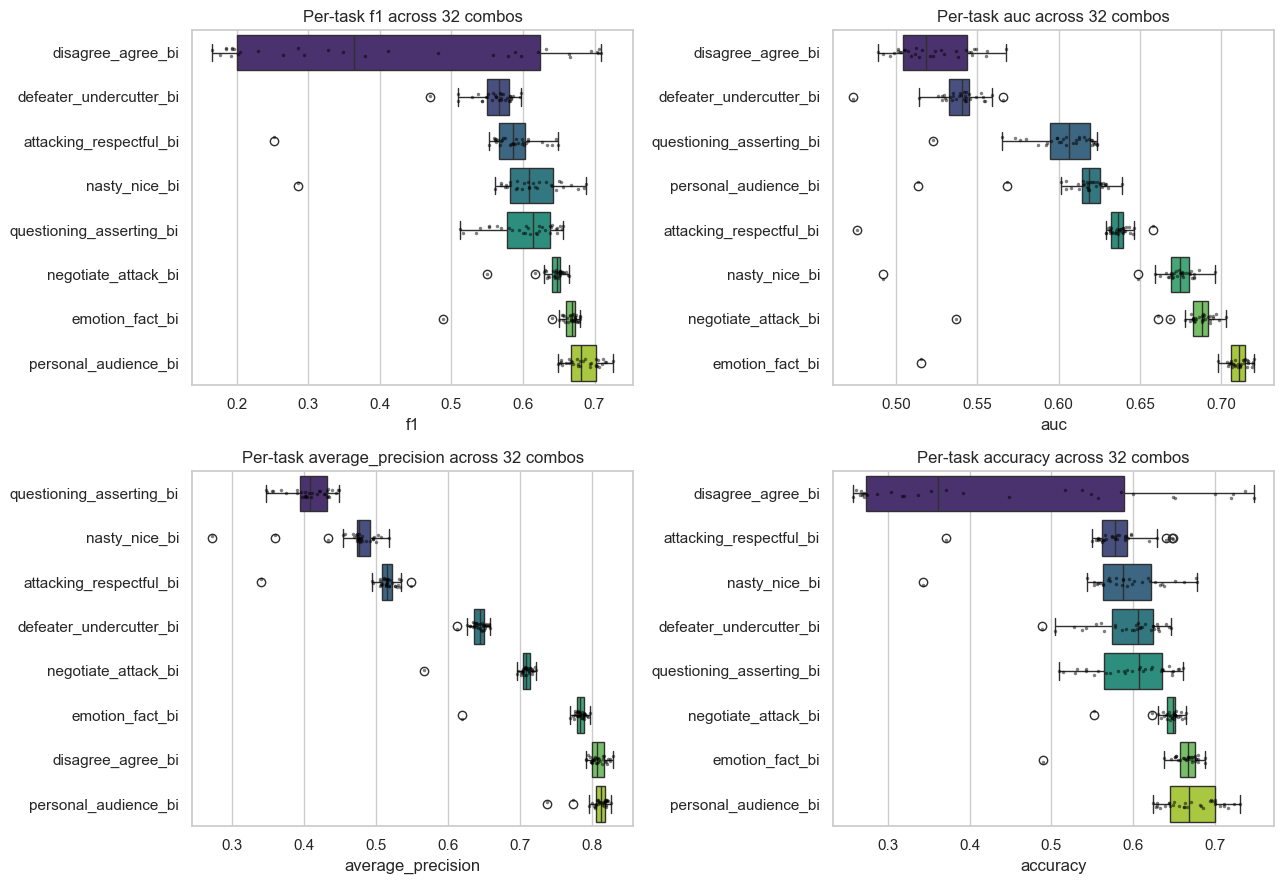

In [56]:
focus_metrics = ["f1", "auc", "average_precision", "accuracy"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, metric in zip(axes.flat, focus_metrics):
    sub = long_df[long_df["metric"] == metric]
    order = sub.groupby("task")["value"].median().sort_values().index
    sns.boxplot(data=sub, y="task", x="value", order=order, ax=ax, palette="viridis")
    sns.stripplot(data=sub, y="task", x="value", order=order, ax=ax, color="black", size=2.5, alpha=0.5)
    ax.set_title(f"Per-task {metric} across 32 combos")
    ax.set_xlabel(metric)
    ax.set_ylabel("")
fig.tight_layout()
plt.show()

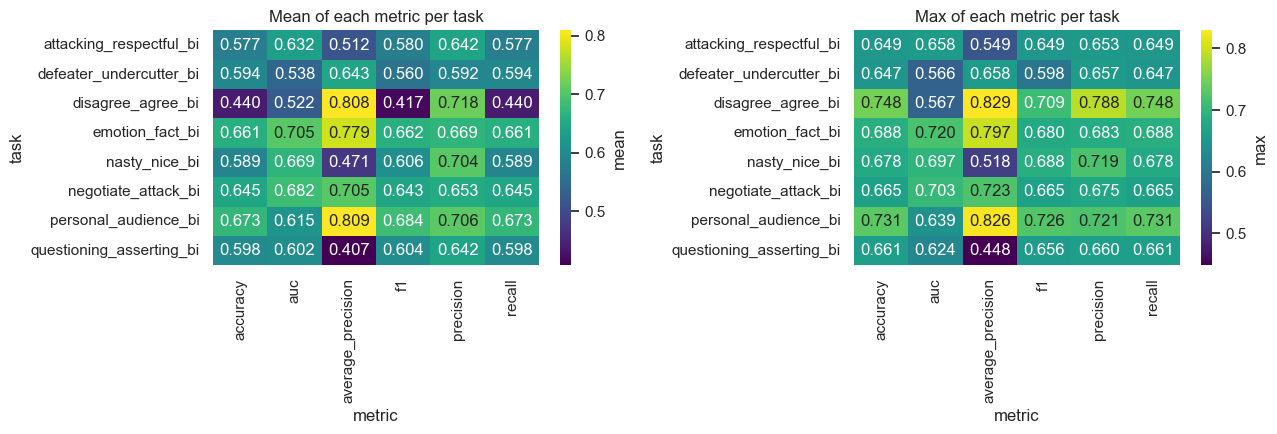

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(per_task_mean, annot=True, fmt=".3f", cmap="viridis", ax=axes[0], cbar_kws={"label": "mean"})
axes[0].set_title("Mean of each metric per task")
sns.heatmap(per_task_max, annot=True, fmt=".3f", cmap="viridis", ax=axes[1], cbar_kws={"label": "max"})
axes[1].set_title("Max of each metric per task")
fig.tight_layout()
plt.show()

In [58]:
rows = []
for task in TASKS:
    col = f"task_{task}_f1"
    best_idx = df[col].idxmax()
    best_row = df.loc[best_idx]
    rows.append({
        "task": task,
        "best_f1": best_row[col],
        "combo_index": int(best_row["combo_index"]),
        "learning_rate": best_row["learning_rate"],
        "weight_decay_rate": best_row["weight_decay_rate"],
        "warmup_fraction": best_row["warmup_fraction"],
        "batch_size": int(best_row["batch_size"]),
        "dropout_rate": best_row["dropout_rate"],
    })
best_per_task = pd.DataFrame(rows).set_index("task").sort_values("best_f1", ascending=False)
print("Best combo for each task by per-task f1:")
best_per_task

Best combo for each task by per-task f1:


,best_f1,combo_index,learning_rate,weight_decay_rate,warmup_fraction,batch_size,dropout_rate
task,,,,,,,
personal_audience_bi,0.7258,5,0.0001,0.0050,0.1000,128,0.2000
disagree_agree_bi,0.7095,7,0.0001,0.0050,0.1000,256,0.2000
nasty_nice_bi,0.6876,6,0.0001,0.0050,0.1000,128,0.4000
emotion_fact_bi,0.6796,26,0.0003,0.0100,0.0500,128,0.4000
negotiate_attack_bi,0.6650,9,0.0001,0.0100,0.0500,128,0.2000
questioning_asserting_bi,0.6565,29,0.0003,0.0100,0.1000,128,0.2000
attacking_respectful_bi,0.6492,5,0.0001,0.0050,0.1000,128,0.2000
defeater_undercutter_bi,0.5976,31,0.0003,0.0100,0.1000,256,0.2000


## 5. Hyperparameter effects on `primary_metric`

Marginal effect of each hyperparameter (mean of `primary_metric` grouped by each value), and a correlation view for numeric hyperparameters.

In [59]:
hparam_value_cols = [
    "learning_rate",
    "weight_decay_rate",
    "warmup_fraction",
    "batch_size",
    "dropout_rate",
    "optimizer",
]
marginals = {}
for hp in hparam_value_cols:
    if df[hp].nunique() <= 1:
        continue
    marginals[hp] = df.groupby(hp)["primary_metric"].agg(["count", "mean", "std", "min", "max"])
for hp, table in marginals.items():
    print(f"-- {hp} --")
    print(table.to_string(float_format=lambda v: f"{v:.4f}"))
    print()

-- learning_rate --
               count   mean    std    min    max
learning_rate                                   
0.0001            16 0.6056 0.0303 0.5403 0.6422
0.0003            16 0.5833 0.0457 0.4692 0.6493

-- weight_decay_rate --
                   count   mean    std    min    max
weight_decay_rate                                   
0.0050                16 0.5975 0.0324 0.5483 0.6422
0.0100                16 0.5914 0.0470 0.4692 0.6493

-- warmup_fraction --
                 count   mean    std    min    max
warmup_fraction                                   
0.0500              16 0.5974 0.0344 0.5483 0.6493
0.1000              16 0.5915 0.0455 0.4692 0.6422

-- batch_size --
            count   mean    std    min    max
batch_size                                   
128            16 0.5882 0.0474 0.4692 0.6493
256            16 0.6007 0.0307 0.5607 0.6422

-- dropout_rate --
              count   mean    std    min    max
dropout_rate                                   
0.

/var/folders/0s/hmhms5h943d0b4ct3l6b61700000gn/T/ipykernel_9515/2521168820.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=hp, y="primary_metric", ax=ax, palette="crest")
/var/folders/0s/hmhms5h943d0b4ct3l6b61700000gn/T/ipykernel_9515/2521168820.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=hp, y="primary_metric", ax=ax, palette="crest")
/var/folders/0s/hmhms5h943d0b4ct3l6b61700000gn/T/ipykernel_9515/2521168820.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x=hp, y="primary_metric", ax=ax, palett

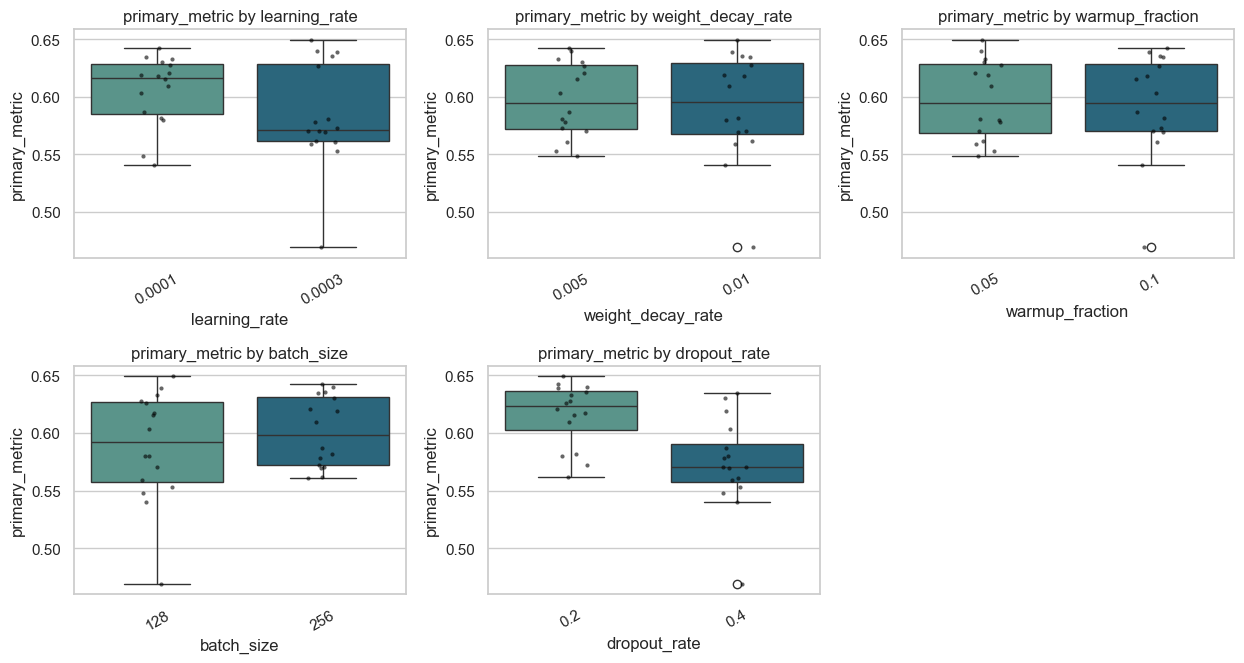

In [60]:
active = [hp for hp, t in marginals.items() if len(t) > 1]
if active:
    n = len(active)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.4 * rows))
    axes = np.atleast_1d(axes).flatten()
    for ax, hp in zip(axes, active):
        sns.boxplot(data=df, x=hp, y="primary_metric", ax=ax, palette="crest")
        sns.stripplot(data=df, x=hp, y="primary_metric", ax=ax, color="black", size=3, alpha=0.6)
        ax.set_title(f"primary_metric by {hp}")
        ax.tick_params(axis="x", rotation=30)
    for ax in axes[len(active):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()
else:
    print("No hyperparameters vary in this grid.")

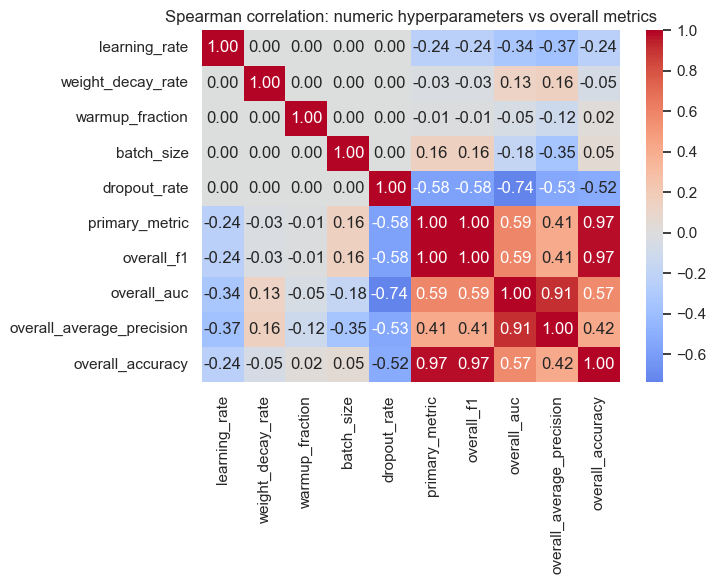

In [61]:
numeric_hp = [hp for hp in ["learning_rate", "weight_decay_rate", "warmup_fraction", "batch_size", "dropout_rate"] if df[hp].nunique() > 1]
corr_cols = numeric_hp + ["primary_metric", "overall_f1", "overall_auc", "overall_average_precision", "overall_accuracy"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation: numeric hyperparameters vs overall metrics")
fig.tight_layout()
plt.show()

## 6. Best hyperparameters per metric

Two notions of "best":

- **Full-combo best** — for each metric, the single hyperparameter combination that maximizes it (treats the grid as a discrete search).
- **Marginal best** — for each individual hyperparameter, the value whose *mean* across the rest of the grid is highest (averages out the other hparams; useful when picking one value at a time).

In [62]:
def best_combo_for_metric(metric_col):
    idx = df[metric_col].idxmax()
    row = df.loc[idx]
    return {
        "metric": metric_col,
        "best_value": row[metric_col],
        "combo_index": int(row["combo_index"]),
        **{hp: row[hp] for hp in HPARAM_VALUE_COLS},
    }

overall_best = pd.DataFrame([best_combo_for_metric(c) for c in OVERALL_COLS]).set_index("metric")
print("6.1 — Best full combo per overall metric:")
overall_best

6.1 — Best full combo per overall metric:


,best_value,combo_index,optimizer,learning_rate,weight_decay_rate,warmup_fraction,batch_size,dropout_rate
metric,,,,,,,,
overall_f1,0.6493,25,adamw,0.0003,0.0100,0.0500,128,0.2000
overall_average_precision,0.6614,5,adamw,0.0001,0.0050,0.1000,128,0.2000
overall_auc,0.6389,9,adamw,0.0001,0.0100,0.0500,128,0.2000
overall_accuracy,0.6533,25,adamw,0.0003,0.0100,0.0500,128,0.2000
primary_metric,0.6493,25,adamw,0.0003,0.0100,0.0500,128,0.2000


In [63]:
task_best_rows = []
for task in TASKS:
    for metric in METRICS_PER_TASK:
        col = f"task_{task}_{metric}"
        if col not in df.columns:
            continue
        idx = df[col].idxmax()
        row = df.loc[idx]
        task_best_rows.append({
            "task": task,
            "metric": metric,
            "best_value": row[col],
            "combo_index": int(row["combo_index"]),
            **{hp: row[hp] for hp in HPARAM_VALUE_COLS},
        })
task_best = pd.DataFrame(task_best_rows)
print("6.2 — Best full combo per (task, metric):")
task_best

6.2 — Best full combo per (task, metric):


,task,metric,best_value,combo_index,optimizer,learning_rate,weight_decay_rate,warmup_fraction,batch_size,dropout_rate
0,attacking_respectful_bi,accuracy,0.6494,5,adamw,0.0001,0.0050,0.1000,128,0.2000
1,attacking_respectful_bi,auc,0.6580,5,adamw,0.0001,0.0050,0.1000,128,0.2000
2,attacking_respectful_bi,average_precision,0.5493,5,adamw,0.0001,0.0050,0.1000,128,0.2000
3,attacking_respectful_bi,f1,0.6492,5,adamw,0.0001,0.0050,0.1000,128,0.2000
4,attacking_respectful_bi,precision,0.6534,21,adamw,0.0003,0.0050,0.1000,128,0.2000
5,attacking_respectful_bi,recall,0.6494,5,adamw,0.0001,0.0050,0.1000,128,0.2000
6,defeater_undercutter_bi,accuracy,0.6468,12,adamw,0.0001,0.0100,0.0500,256,0.4000
7,defeater_undercutter_bi,auc,0.5655,9,adamw,0.0001,0.0100,0.0500,128,0.2000
8,defeater_undercutter_bi,average_precision,0.6578,16,adamw,0.0001,0.0100,0.1000,256,0.4000
9,defeater_undercutter_bi,f1,0.5976,31,adamw,0.0003,0.0100,0.1000,256,0.2000


In [64]:
# How often does each hparam value appear among the best combos for the per-task metrics?
freq_rows = []
for hp in HPARAM_VALUE_COLS:
    counts = task_best[hp].value_counts()
    for value, count in counts.items():
        freq_rows.append({"hparam": hp, "value": value, "count": int(count)})
best_value_freq = pd.DataFrame(freq_rows)
print("6.2b — Frequency of hparam values among per-(task,metric) winners "
      f"(out of {len(task_best)} task-metric slots):")
best_value_freq.pivot_table(index="hparam", columns="value", values="count", fill_value=0)

6.2b — Frequency of hparam values among per-(task,metric) winners (out of 48 task-metric slots):


value,0.0001,0.0003,0.0050,0.0100,0.0500,0.1000,0.2000,0.4000,128,256,adamw
hparam,,,,,,,,,,,
batch_size,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,39.0000,9.0000,0.0000
dropout_rate,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,36.0000,12.0000,0.0000,0.0000,0.0000
learning_rate,36.0000,12.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
optimizer,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,48.0000
warmup_fraction,0.0000,0.0000,0.0000,0.0000,18.0000,30.0000,0.0000,0.0000,0.0000,0.0000,0.0000
weight_decay_rate,0.0000,0.0000,27.0000,21.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [65]:
def marginal_best(metric_col):
    """For each hparam, return the value with the highest mean of metric_col."""
    out = {}
    for hp in HPARAM_VALUE_COLS:
        if df[hp].nunique() <= 1:
            out[hp] = df[hp].iloc[0]
            continue
        grouped = df.groupby(hp)[metric_col].mean()
        out[hp] = grouped.idxmax()
    return out

# Build a (metric x hparam) table of marginal-best values: overall metrics + per-task metrics.
metric_cols_all = OVERALL_COLS + TASK_COLS
marginal_rows = []
for metric_col in metric_cols_all:
    row = {"metric": metric_col}
    row.update(marginal_best(metric_col))
    marginal_rows.append(row)
marginal_best_table = pd.DataFrame(marginal_rows).set_index("metric")
print(f"6.3 — Marginal best hparam value per metric ({len(marginal_best_table)} metrics x "
      f"{len(HPARAM_VALUE_COLS)} hparams):")
marginal_best_table

6.3 — Marginal best hparam value per metric (53 metrics x 6 hparams):


,optimizer,learning_rate,weight_decay_rate,warmup_fraction,batch_size,dropout_rate
metric,,,,,,
overall_f1,adamw,0.0001,0.0050,0.0500,256,0.2000
overall_average_precision,adamw,0.0001,0.0050,0.0500,128,0.2000
overall_auc,adamw,0.0001,0.0050,0.0500,256,0.2000
overall_accuracy,adamw,0.0001,0.0050,0.0500,256,0.2000
primary_metric,adamw,0.0001,0.0050,0.0500,256,0.2000
task_attacking_respectful_bi_accuracy,adamw,0.0001,0.0050,0.0500,128,0.2000
task_attacking_respectful_bi_precision,adamw,0.0001,0.0050,0.1000,256,0.2000
task_attacking_respectful_bi_recall,adamw,0.0001,0.0050,0.0500,128,0.2000
task_attacking_respectful_bi_f1,adamw,0.0001,0.0050,0.0500,256,0.2000


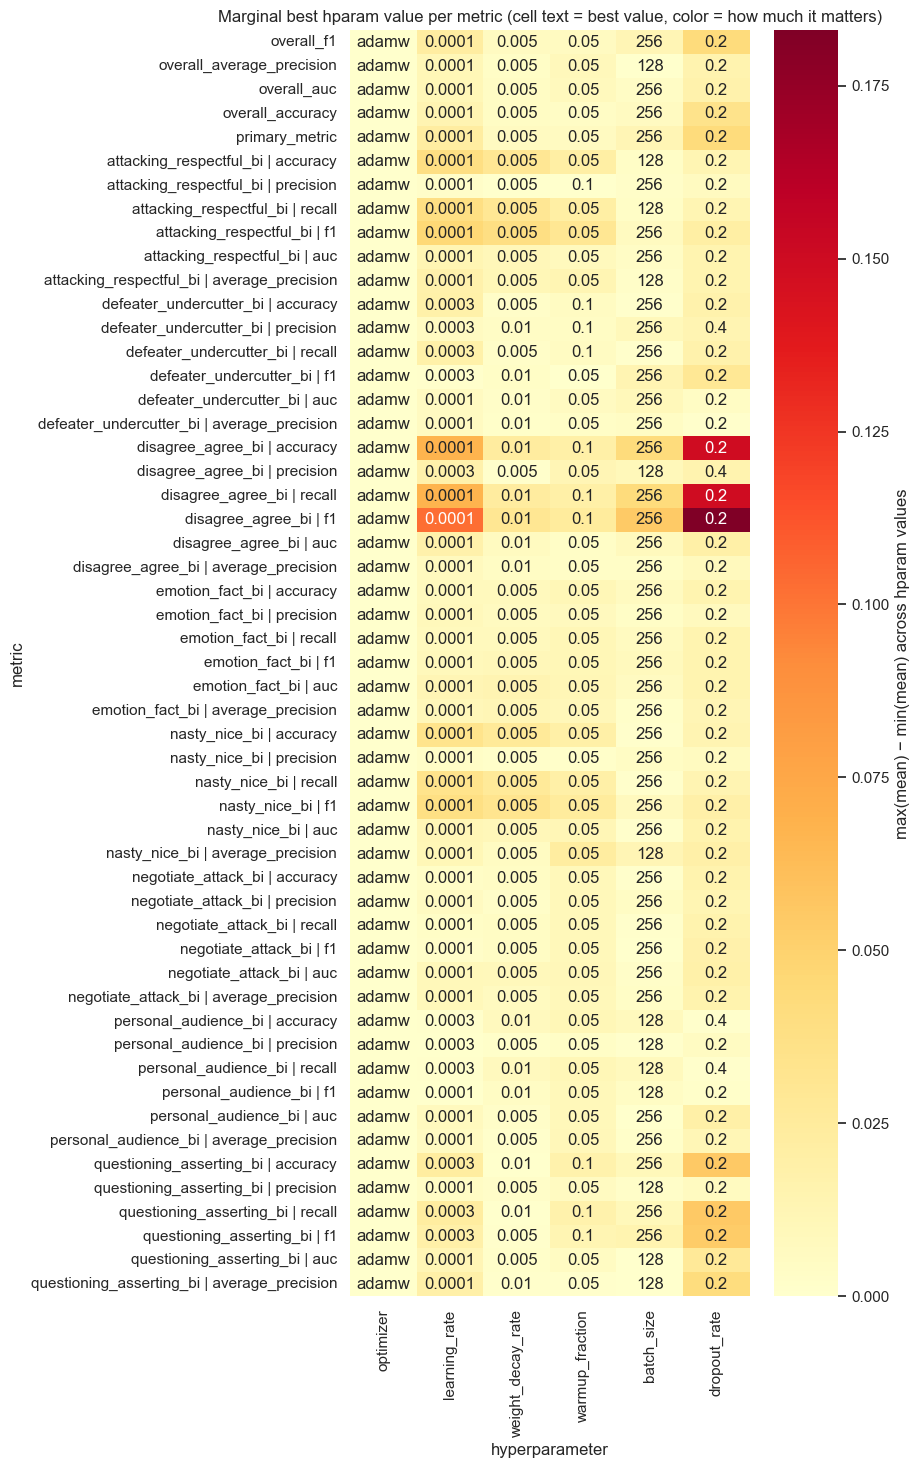

In [66]:
# Visualize 6.3 as a heatmap. Each cell shows the marginal-best value for that (metric, hparam),
# colored by the *improvement* (max mean - min mean) so you can see how much the choice matters.
def marginal_delta(metric_col, hp):
    if df[hp].nunique() <= 1:
        return 0.0
    grouped = df.groupby(hp)[metric_col].mean()
    return float(grouped.max() - grouped.min())

delta_table = pd.DataFrame(
    {hp: [marginal_delta(m, hp) for m in metric_cols_all] for hp in HPARAM_VALUE_COLS},
    index=metric_cols_all,
)
annot_table = marginal_best_table.astype(str)

# Friendly row labels: keep overall as-is, shorten task rows to "task | metric".
def pretty_metric(col):
    if col in OVERALL_COLS:
        return col
    task, metric = parse_task_col(col)
    return f"{task} | {metric}"

pretty_index = [pretty_metric(c) for c in metric_cols_all]
delta_table.index = pretty_index
annot_table.index = pretty_index

fig, ax = plt.subplots(figsize=(9, max(6, 0.28 * len(delta_table))))
sns.heatmap(
    delta_table,
    annot=annot_table.values,
    fmt="",
    cmap="YlOrRd",
    cbar_kws={"label": "max(mean) − min(mean) across hparam values"},
    ax=ax,
)
ax.set_title("Marginal best hparam value per metric (cell text = best value, color = how much it matters)")
ax.set_xlabel("hyperparameter")
ax.set_ylabel("metric")
fig.tight_layout()
plt.show()

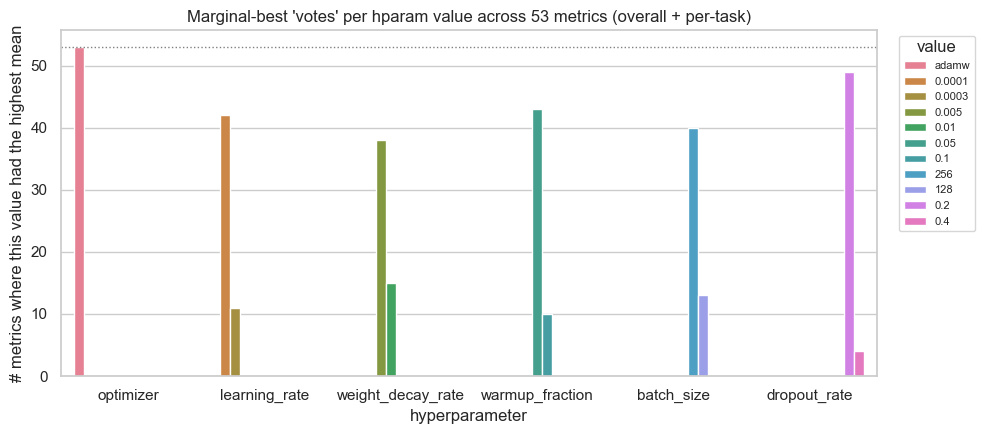

Tabular view (rows sum to # metrics):


value,0.0001,0.0003,0.005,0.01,0.05,0.1,0.2,0.4,128,256,adamw
hparam,,,,,,,,,,,
batch_size,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,13.0000,40.0000,0.0000
dropout_rate,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,49.0000,4.0000,0.0000,0.0000,0.0000
learning_rate,42.0000,11.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
optimizer,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,53.0000
warmup_fraction,0.0000,0.0000,0.0000,0.0000,43.0000,10.0000,0.0000,0.0000,0.0000,0.0000,0.0000
weight_decay_rate,0.0000,0.0000,38.0000,15.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [67]:
# Count, across ALL metrics (overall + per-task), how often each hparam value wins on the marginal view.
votes_rows = []
for hp in HPARAM_VALUE_COLS:
    counts = marginal_best_table[hp].value_counts()
    for value, count in counts.items():
        votes_rows.append({"hparam": hp, "value": str(value), "wins": int(count)})
votes = pd.DataFrame(votes_rows)
total_metrics = len(marginal_best_table)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(
    data=votes,
    x="hparam",
    y="wins",
    hue="value",
    ax=ax,
)
ax.axhline(total_metrics, color="grey", linestyle=":", linewidth=1)
ax.set_title(f"Marginal-best 'votes' per hparam value across {total_metrics} metrics (overall + per-task)")
ax.set_ylabel("# metrics where this value had the highest mean")
ax.set_xlabel("hyperparameter")
ax.legend(title="value", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

print("Tabular view (rows sum to # metrics):")
votes.pivot_table(index="hparam", columns="value", values="wins", fill_value=0)

## Summary cell

Quick textual recap printed for convenience.

In [68]:
best = df.loc[df["primary_metric"].idxmax()]
print(f"Number of combos: {len(df)}")
print(f"primary_metric: mean={df['primary_metric'].mean():.4f}  std={df['primary_metric'].std():.4f}  min={df['primary_metric'].min():.4f}  max={df['primary_metric'].max():.4f}")
print()
print("Best combo:")
for col in HPARAM_COLS + OVERALL_COLS:
    val = best[col]
    print(f"  {col}: {val:.4f}" if isinstance(val, float) else f"  {col}: {val}")
print()
print("Per-task f1 mean (across all combos):")
for task in TASKS:
    col = f"task_{task}_f1"
    print(f"  {task:<32s} mean={df[col].mean():.4f}  max={df[col].max():.4f}")

Number of combos: 32
primary_metric: mean=0.5944  std=0.0398  min=0.4692  max=0.6493

Best combo:
  combo_index: 25
  optimizer: adamw
  learning_rate: 0.0003
  weight_decay_rate: 0.0100
  warmup_fraction: 0.0500
  batch_size: 128
  dropout_rate: 0.2000
  overall_f1: 0.6493
  overall_average_precision: 0.6482
  overall_auc: 0.6251
  overall_accuracy: 0.6533
  primary_metric: 0.6493

Per-task f1 mean (across all combos):
  attacking_respectful_bi          mean=0.5798  max=0.6492
  defeater_undercutter_bi          mean=0.5603  max=0.5976
  disagree_agree_bi                mean=0.4167  max=0.7095
  emotion_fact_bi                  mean=0.6617  max=0.6796
  nasty_nice_bi                    mean=0.6057  max=0.6876
  negotiate_attack_bi              mean=0.6433  max=0.6650
  personal_audience_bi             mean=0.6842  max=0.7258
  questioning_asserting_bi         mean=0.6040  max=0.6565
